# GFS forecasts for case studies: 
https://tds.gdex.ucar.edu/thredds/catalog/catalog.html

### Fully general approach: from a file by file archive 2015-01-15 to present 

https://tds.gdex.ucar.edu/thredds/catalog/catalog_d084001.html. 

#### Simpler access to analysis (83002) or short leads (0,3,6,9H - 83003, from 2015 July) in year-by-year aggregations

xr.open_dataset('https://tds.gdex.ucar.edu/thredds/dodsC/aggregations/g/d083002/2/d083002_Grib2-2015')

xr.open_dataset('https://tds.gdex.ucar.edu/thredds/dodsC/aggregations/g/d083003/1/d083003-2015')



In [4]:
# Imports 

import multiprocessing
multiprocessing.set_start_method("fork", force=True)  # macOS/Linux only
from concurrent.futures import ThreadPoolExecutor, as_completed

import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import xarray as xr
import pandas as pd
import time
import numpy as np 

https://tds.gdex.ucar.edu/thredds/dodsC/files/g/d084001/2018/20181228/gfs.0p25.2018122800.f096.grib2
https://tds.gdex.ucar.edu/thredds/dodsC/files/g/d084001/2018/20181229/gfs.0p25.2018122900.f072.grib2
https://tds.gdex.ucar.edu/thredds/dodsC/files/g/d084001/2018/20181230/gfs.0p25.2018123000.f048.grib2
https://tds.gdex.ucar.edu/thredds/dodsC/files/g/d084001/2018/20181231/gfs.0p25.2018123100.f024.grib2
https://tds.gdex.ucar.edu/thredds/dodsC/files/g/d084001/2019/20190101/gfs.0p25.2019010100.f000.grib2
https://tds.gdex.ucar.edu/thredds/dodsC/files/g/d084001/2018/20181229/gfs.0p25.2018122900.f096.grib2
https://tds.gdex.ucar.edu/thredds/dodsC/files/g/d084001/2018/20181230/gfs.0p25.2018123000.f072.grib2
https://tds.gdex.ucar.edu/thredds/dodsC/files/g/d084001/2018/20181231/gfs.0p25.2018123100.f048.grib2
https://tds.gdex.ucar.edu/thredds/dodsC/files/g/d084001/2019/20190101/gfs.0p25.2019010100.f024.grib2
https://tds.gdex.ucar.edu/thredds/dodsC/files/g/d084001/2019/20190102/gfs.0p25.2019010200.f

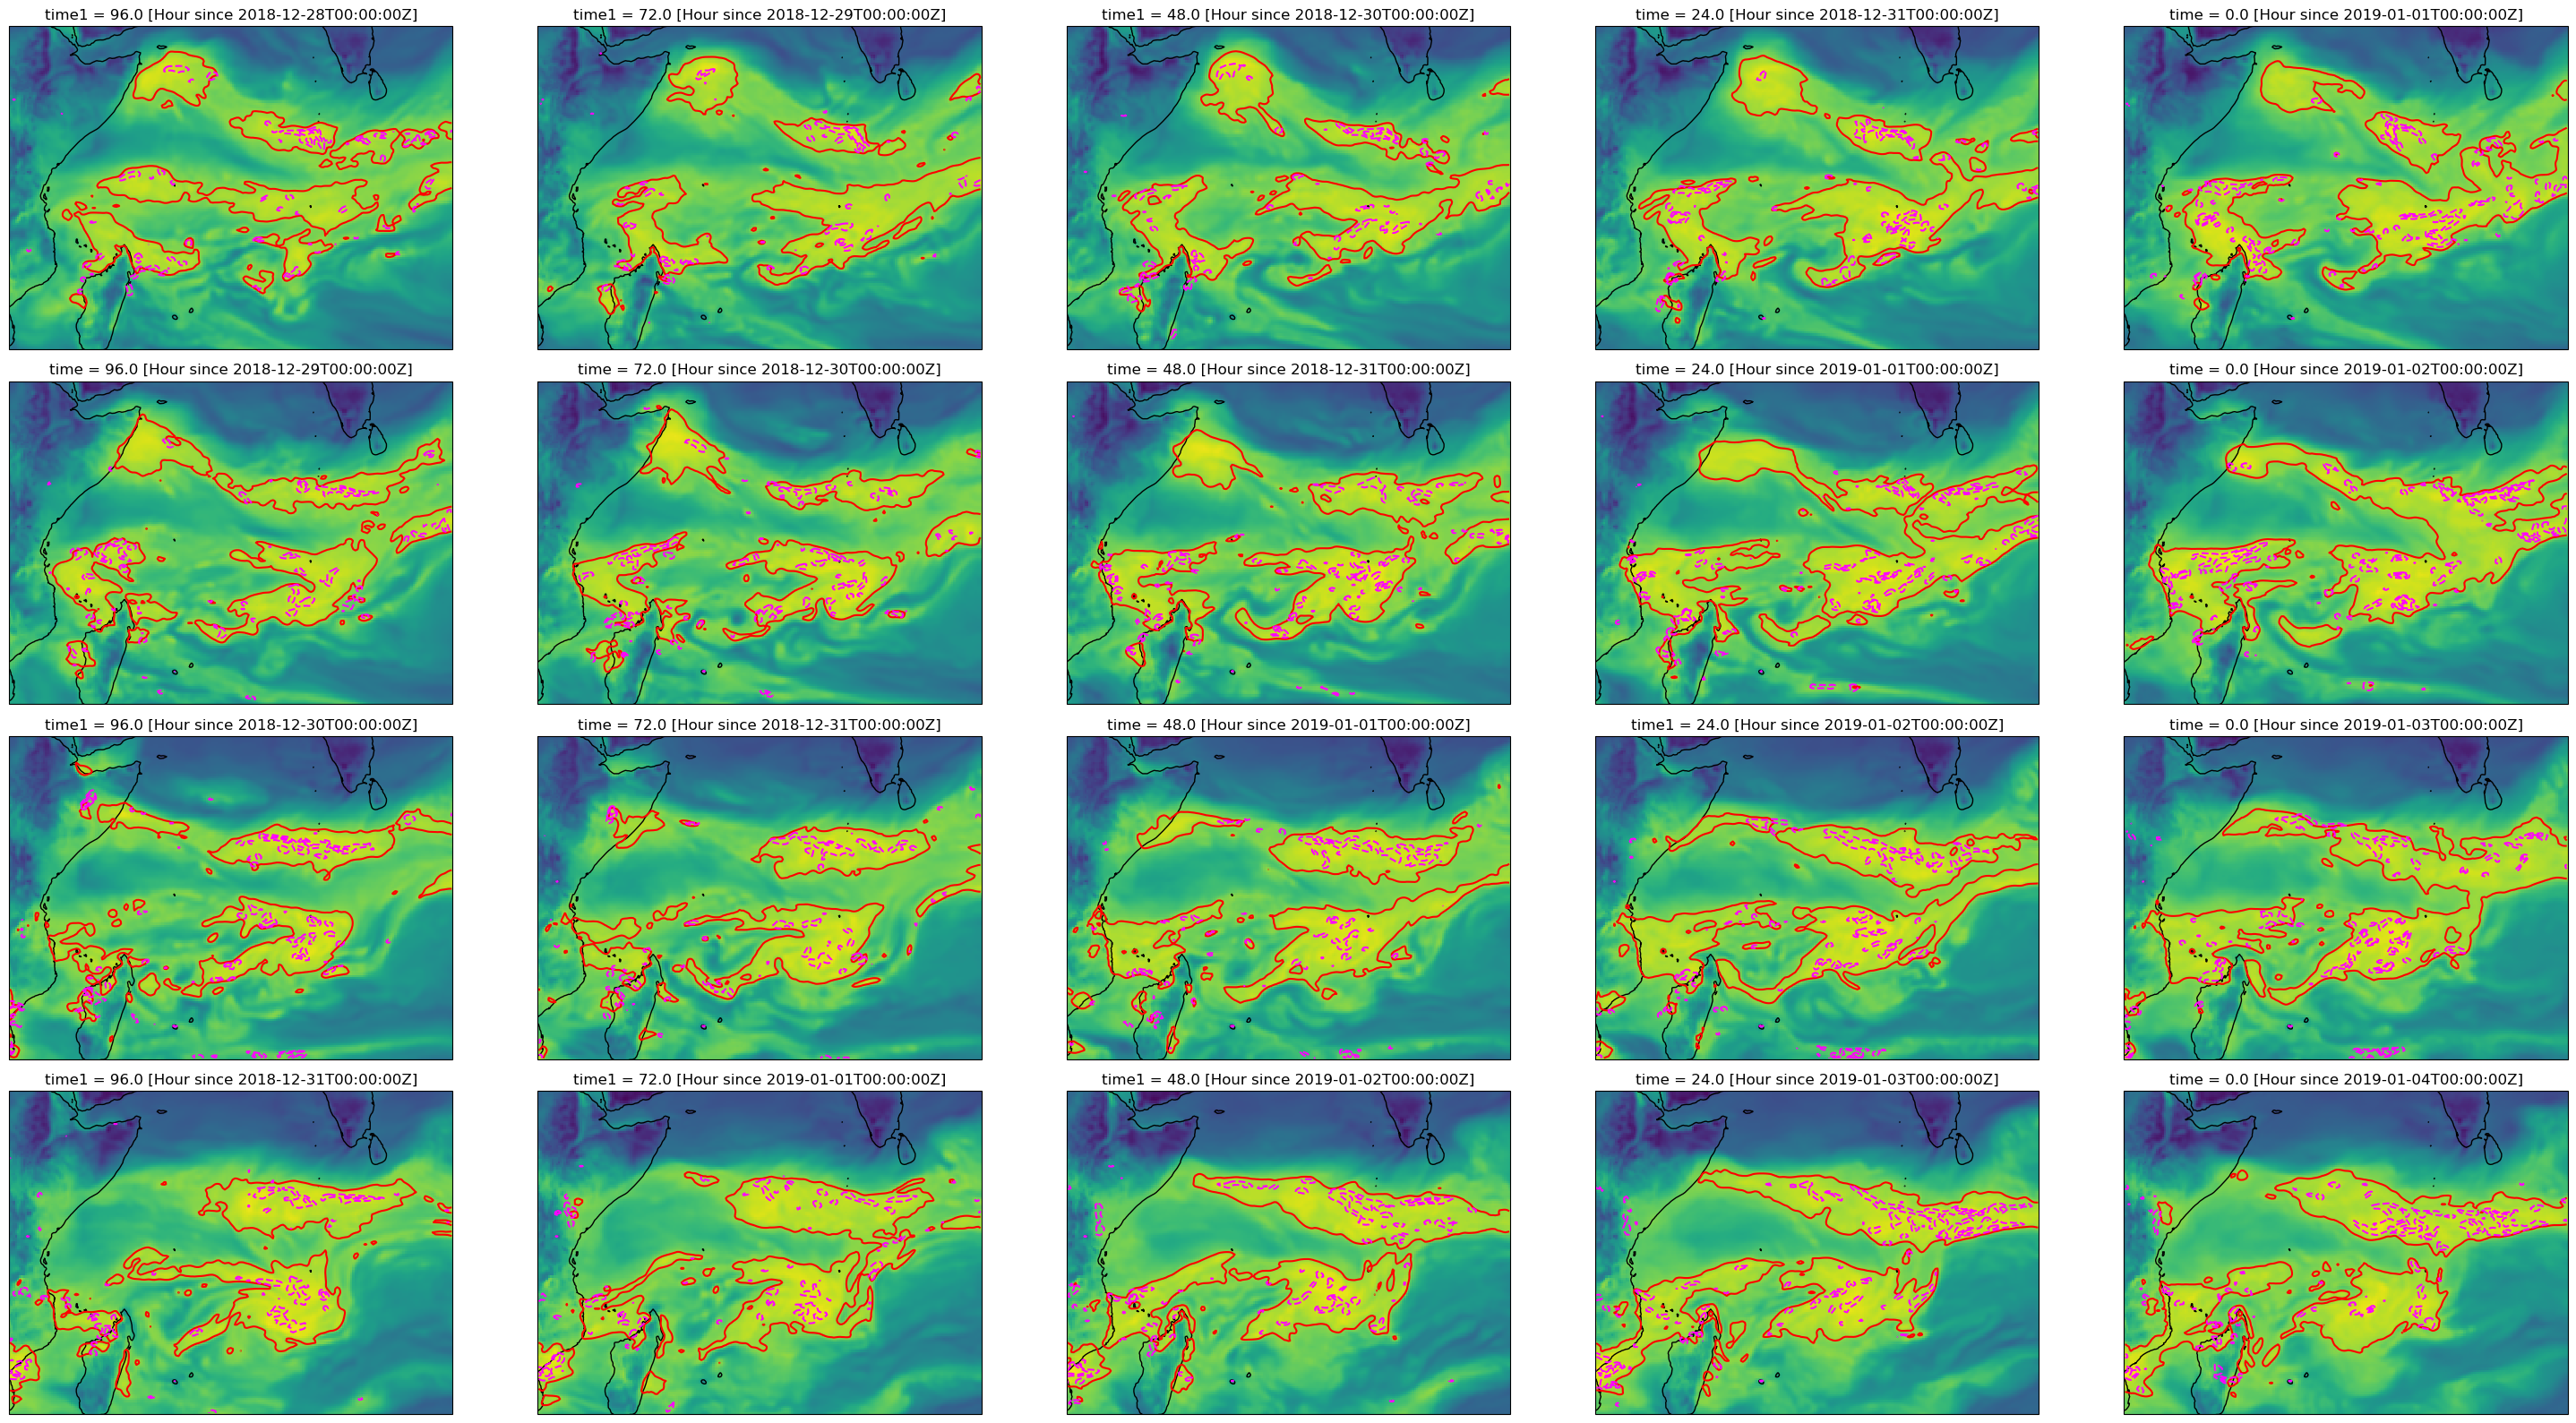

In [9]:
# Loop over times and leadtimes, making a matrix of plots 
# Right column is a series of analyses, each row leads up to it 

#verification_time_final = "2015-06-15 00:00"
verification_time_final = "2019-01-04 00:00"

vt_offsets = [-72, -48, -24, 0]            # times for verification times  
lead_hours = 24 * np.arange(0, 5)          # from 0, 5 days every 24 hours 
lead_hours = 24 * np.arange(0, 5)[::-1]    # reversed for plot [96, 72, 48, 24, 0]

# Create figure with Cartopy projection, with nrows, ncolumns arguments
fig, axes = plt.subplots(len(vt_offsets), len(lead_hours), 
                         subplot_kw={'projection': ccrs.PlateCarree()}, 
                         figsize=(30, 16))

latslice =slice(15, -25) # WEIO box 
lonslice =slice(35, 90)

# Smaller set of variables: enough to make horizontal moisture flux and/or vertical advection 
vars_to_keep = [
    'Geopotential_height_surface',
    'Precipitable_water_entire_atmosphere_single_layer',
    'Vertical_velocity_pressure_isobaric']  #,
#    'u-component_of_wind_isobaric',
#    'v-component_of_wind_isobaric',
#    'Dewpoint_temperature_height_above_ground']


############# TOP ROW OF PLOTS: ANALYSES ##############
# Loop over verification_times datasets for top row of plots 

vt = pd.Timestamp(verification_time_final)

for irow, vt_offset in enumerate(vt_offsets):
    verif_time = vt + pd.Timedelta(hours=vt_offset)

# A second loop over leads to fill the rows 
    for icol,lead in enumerate(lead_hours):
        run_time = verif_time - pd.Timedelta(hours=lead)

# OK we have the URL maker's inputs.
        url = (
            f"https://tds.gdex.ucar.edu/thredds/dodsC/files/g/d084001/"
            f"{run_time.year}/{run_time.year}{run_time.month:02d}{run_time.day:02d}/"
            f"gfs.0p25.{run_time.year}{run_time.month:02d}{run_time.day:02d}"
            f"{run_time.hour:02d}.f{lead:03d}.grib2"
        )
        #print(f"verif={verif_time}  run={run_time}  lead={lead:3d}h")
        print(url)
        #print('row, col ',irow, icol) 

        ds = xr.open_dataset(url, decode_times=False, decode_coords=False)        
        
# Select geographic window, and vertically average omega, for these forecasts  
        isobaric_dim = next(d for d in ds.Vertical_velocity_pressure_isobaric.dims if "isobaric" in d)
        CVV_WEIOa = ds.Vertical_velocity_pressure_isobaric. \
             sel(lat=latslice, lon=lonslice).squeeze().mean(dim=isobaric_dim)
        CWV_WEIOa = ds.Precipitable_water_entire_atmosphere_single_layer. \
             sel(lat=latslice, lon=lonslice).squeeze()

        ax = axes[irow, icol] 

        CWV_WEIOa.plot(ax=ax, vmin=0, vmax=65, add_colorbar=False) #, cbar_kwargs={'shrink': 0.5})
        CWV_WEIOa.plot.contour(ax=ax, levels=[54], colors='red')
        CVV_WEIOa.plot.contour(ax=ax, levels=[-1,-0.5,-0.25], colors='magenta')
        ax.coastlines()

plt.tight_layout()
plt.savefig('/Users/bmapes/Downloads/'+verification_time_final+'.pdf')


In [40]:
# Make it a function, so I can loop-call it for multiple dates. 

from matplotlib.backends.backend_pdf import PdfPages

def plot_gfs_page(verification_time_final, vt_offsets, lead_hours, latslice, lonslice, vars_to_keep):
    lead_hours_plot = lead_hours[::-1]
    fig, axes = plt.subplots(
        len(vt_offsets), len(lead_hours_plot),
        subplot_kw={'projection': ccrs.PlateCarree()},
        figsize=(30, 16)
    )
    vt = pd.Timestamp(verification_time_final)
    for irow, vt_offset in enumerate(vt_offsets):
        verif_time = vt + pd.Timedelta(hours=vt_offset)
        for icol, lead in enumerate(lead_hours_plot):
            run_time = verif_time - pd.Timedelta(hours=int(lead))
            url = (
                f"https://tds.gdex.ucar.edu/thredds/dodsC/files/g/d084001/"
                f"{run_time.year}/{run_time.year}{run_time.month:02d}{run_time.day:02d}/"
                f"gfs.0p25.{run_time.year}{run_time.month:02d}{run_time.day:02d}"
                f"{run_time.hour:02d}.f{lead:03d}.grib2"
            )
            print(f"verif={verif_time}  run={run_time}  lead={lead:3d}h  [{irow},{icol}]")
            try:
                ds = xr.open_dataset(url, decode_times=False, decode_coords=False)
                isobaric_dim = next(d for d in ds.Vertical_velocity_pressure_isobaric.dims if "isobaric" in d)
                CVV = ds.Vertical_velocity_pressure_isobaric \
                        .sel(lat=latslice, lon=lonslice).squeeze().mean(dim=isobaric_dim)
                CWV = ds.Precipitable_water_entire_atmosphere_single_layer \
                        .sel(lat=latslice, lon=lonslice).squeeze()
                ax = axes[irow, icol]
                CWV.plot(ax=ax, vmin=0, vmax=65, add_colorbar=False)
                CWV.plot.contour(ax=ax, levels=[54], colors='red')
                CVV.plot.contour(ax=ax, levels=[-1, -0.5, -0.25], colors='magenta')
                ax.coastlines()
                ax.set_title(f"verif={verif_time.strftime('%m/%d %Hz')}  lead={lead}h")
            except Exception as e:
                print(f"  FAILED: {e}")
                axes[irow, icol].set_visible(False)

    fig.suptitle(f"GFS forecasts valid through {verification_time_final}", fontsize=14)
    plt.tight_layout()
    return fig

In [41]:
# --- loop over # Snigdha's 2016 end dates dates, accumulate into one PDF ---
verification_dates = [
    "2016-01-26 00:00:00",  # 2016-01-25 22:30:00 → rounds up
    "2016-01-28 00:00:00",  # 2016-01-27 22:30:00 → rounds up
    "2016-03-26 00:00:00",  # 2016-03-26 5:30:00 → rounds down
    "2016-04-04 00:00:00",  # 2016-04-03 19:30:00 → rounds up
    "2016-04-05 00:00:00",  # 2016-04-05 14:30:00 → rounds up
    "2016-04-15 00:00:00",  # 2016-04-15 7:30:00 → rounds down
    "2016-04-30 00:00:00",  # 2016-04-30 18:30:00 → rounds up
    "2016-05-28 00:00:00",  # 2016-05-28 12:30:00 → rounds up (at exactly 12:30, typically rounds up)
    "2016-06-02 00:00:00",  # 2016-06-02 4:30:00 → rounds down
    "2016-06-11 00:00:00",  # 2016-06-11 13:30:00 → rounds up
    "2016-07-16 00:00:00",  # 2016-07-16 3:30:00 → rounds down
    "2016-08-08 00:00:00",  # 2016-08-07 15:30:00 → rounds up
    "2016-10-10 00:00:00",  # 2016-10-10 8:30:00 → rounds down
    "2016-11-10 00:00:00",  # 2016-11-10 1:30:00 → rounds down
    "2016-12-06 00:00:00",  # 2016-12-05 15:30:00 → rounds up
    "2016-12-16 00:00:00",  # 2016-12-15 13:30:00 → rounds up
    "2016-12-17 00:00:00",  # 2016-12-17 9:30:00 → rounds down
    "2016-12-21 00:00:00",  # 2016-12-20 14:30:00 → rounds up
    "2016-12-23 00:00:00",  # 2016-12-22 13:30:00 → rounds up
    "2016-12-25 00:00:00",  # 2016-12-25 5:30:00 → rounds down
    "2016-12-30 00:00:00"   # 2016-12-29 21:30:00 → rounds up
]   

vt_offsets  = [-72, -48, -24, 0]
lead_hours  = 24 * np.arange(0, 5)
latslice    = slice(15, -25)
lonslice    = slice(35, 90)
vars_to_keep = [
    'Geopotential_height_surface',
    'Precipitable_water_entire_atmosphere_single_layer',
    'Vertical_velocity_pressure_isobaric',
]


pdf_path = '/Users/bmapes/Downloads/GFScasts_multipage.pdf'
with PdfPages(pdf_path) as pdf:
    for vt_final in verification_dates:
        fig = plot_gfs_page(vt_final, vt_offsets, lead_hours, latslice, lonslice, vars_to_keep)
        pdf.savefig(fig)
        plt.close(fig)   # free memory before next page
        print(f"  saved page for {vt_final}")

print(f"Done — PDF written to {pdf_path}")

verif=2016-01-23 00:00:00  run=2016-01-19 00:00:00  lead= 96h  [0,0]
verif=2016-01-23 00:00:00  run=2016-01-20 00:00:00  lead= 72h  [0,1]
verif=2016-01-23 00:00:00  run=2016-01-21 00:00:00  lead= 48h  [0,2]
verif=2016-01-23 00:00:00  run=2016-01-22 00:00:00  lead= 24h  [0,3]
verif=2016-01-23 00:00:00  run=2016-01-23 00:00:00  lead=  0h  [0,4]
verif=2016-01-24 00:00:00  run=2016-01-20 00:00:00  lead= 96h  [1,0]
verif=2016-01-24 00:00:00  run=2016-01-21 00:00:00  lead= 72h  [1,1]
verif=2016-01-24 00:00:00  run=2016-01-22 00:00:00  lead= 48h  [1,2]
verif=2016-01-24 00:00:00  run=2016-01-23 00:00:00  lead= 24h  [1,3]
verif=2016-01-24 00:00:00  run=2016-01-24 00:00:00  lead=  0h  [1,4]
verif=2016-01-25 00:00:00  run=2016-01-21 00:00:00  lead= 96h  [2,0]
verif=2016-01-25 00:00:00  run=2016-01-22 00:00:00  lead= 72h  [2,1]
verif=2016-01-25 00:00:00  run=2016-01-23 00:00:00  lead= 48h  [2,2]
verif=2016-01-25 00:00:00  run=2016-01-24 00:00:00  lead= 24h  [2,3]
verif=2016-01-25 00:00:00  run=201

In [42]:
!open /Users/bmapes/Downloads/GFScasts_multipage.pdf

In [ ]:
ds.Dewpoint_temperature_height_above_ground